<a href="https://colab.research.google.com/github/ahmed-abo-el3ela/assymint-of-data-science-code/blob/main/Project_(1)%20OF%20churn%20predict%20in%20banking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


📉 Bank Customer Churn — Prediction & Analysis
Goal: Predict which customers are likely to churn (cancel their telecom service) and surface the business drivers behind churn, so that retention teams can act before customers leave.

Dataset: IBM Telco Customer Churn — 7,043 customers, 21 attributes (demographics, account info, subscribed services, billing).

Approach

Clean & prepare the raw data
Explore churn patterns visually (EDA)
Engineer features and handle class imbalance (SMOTE)
Train & tune 6 classification models
Compare models on Accuracy, Precision, Recall, F1 and ROC-AUC
Identify the strongest churn drivers

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score


In [ ]:
df = pd.read_csv('/content/train.csv')

In [ ]:
df.head()

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15674932,Okwudilichukwu,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,0
1,1,15749177,Okwudiliolisa,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,0
2,2,15694510,Hsueh,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,0
3,3,15741417,Kao,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,0
4,4,15766172,Chiemenam,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14222 entries, 0 to 14221
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               14222 non-null  int64  
 1   CustomerId       14222 non-null  int64  
 2   Surname          14222 non-null  object 
 3   CreditScore      14222 non-null  int64  
 4   Geography        14222 non-null  object 
 5   Gender           14222 non-null  object 
 6   Age              14222 non-null  float64
 7   Tenure           14222 non-null  int64  
 8   Balance          14222 non-null  float64
 9   NumOfProducts    14222 non-null  int64  
 10  HasCrCard        14222 non-null  float64
 11  IsActiveMember   14222 non-null  float64
 12  EstimatedSalary  14222 non-null  float64
 13  Exited           14222 non-null  int64  
dtypes: float64(5), int64(6), object(3)
memory usage: 1.5+ MB


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe(include='number')

,id,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,14222.000000,1.422200e+04,14222.000000,14222.000000,14222.000000,14222.000000,14222.000000,14222.000000,14222.000000,14222.000000,14222.000000
mean,7110.500000,1.569172e+07,656.398256,37.991773,5.011391,55273.057464,1.552384,0.762129,0.499789,112965.117603,0.207355
std,4105.682099,7.176351e+04,80.749324,8.902499,2.816920,62759.893449,0.545933,0.425795,0.500018,50224.588673,0.405426
min,0.000000,1.556571e+07,359.000000,18.000000,0.000000,0.000000,1.000000,0.000000,0.000000,11.580000,0.000000
25%,3555.250000,1.563318e+07,597.000000,32.000000,3.000000,0.000000,1.000000,1.000000,0.000000,74850.840000,0.000000
50%,7110.500000,1.568947e+07,659.000000,37.000000,5.000000,0.000000,2.000000,1.000000,0.000000,119079.405000,0.000000
75%,10665.750000,1.575732e+07,710.000000,42.000000,7.000000,119787.760000,2.000000,1.000000,1.000000,155786.327500,0.000000
max,14221.000000,1.581563e+07,850.000000,82.000000,10.000000,250898.090000,4.000000,1.000000,1.000000,199992.480000,1.000000


In [ ]:
df.describe(include='object')

,Surname,Geography,Gender
count,14222,14222,14222
unique,1696,3,2
top,Hsia,France,Male
freq,202,8274,7994


## Data Cleaning

In [ ]:
df = df.drop(columns=['id', 'CustomerId', 'Surname'])

In [ ]:

cat_cols = list(df.select_dtypes(include='object').columns)
for col in cat_cols:
    print(f'{col:18s}: {df[col].unique()}')

Geography         : ['France' 'Spain' 'Germany']
Gender            : ['Male' 'Female']


In [ ]:
label_encoder = LabelEncoder()
df['Geography'] = label_encoder.fit_transform(df['Geography'])


In [ ]:
df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})

EDA

/tmp/ipykernel_456/2582746329.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='Exited', data=df, palette=['#2E86AB', '#E63946'])
/tmp/ipykernel_456/2582746329.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Not Churn', 'Churn'])


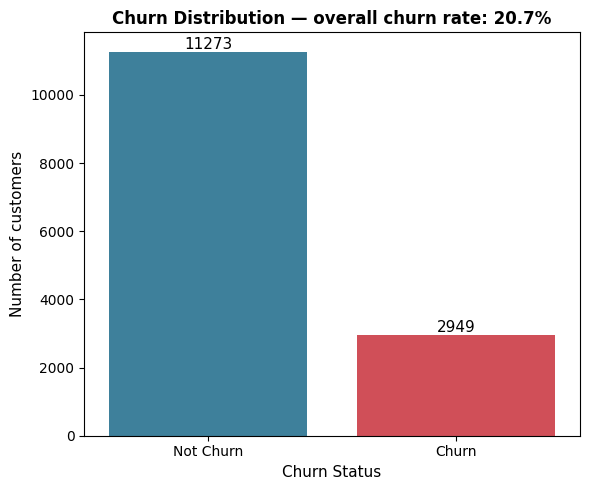

In [ ]:
churn_rate = df['Exited'].mean() * 100

plt.figure(figsize=(6, 5))
ax = sns.countplot(x='Exited', data=df, palette=['#2E86AB', '#E63946'])
ax.set_xticklabels(['Not Churn', 'Churn'])
plt.title(f'Churn Distribution — overall churn rate: {churn_rate:.1f}%', fontweight='bold', fontsize=12)
plt.ylabel('Number of customers', fontsize=11)
plt.xlabel('Churn Status', fontsize=11)

# إضافة القيم فوق الأعمدة
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.savefig('churn_distribution.png', dpi=150)
plt.show()

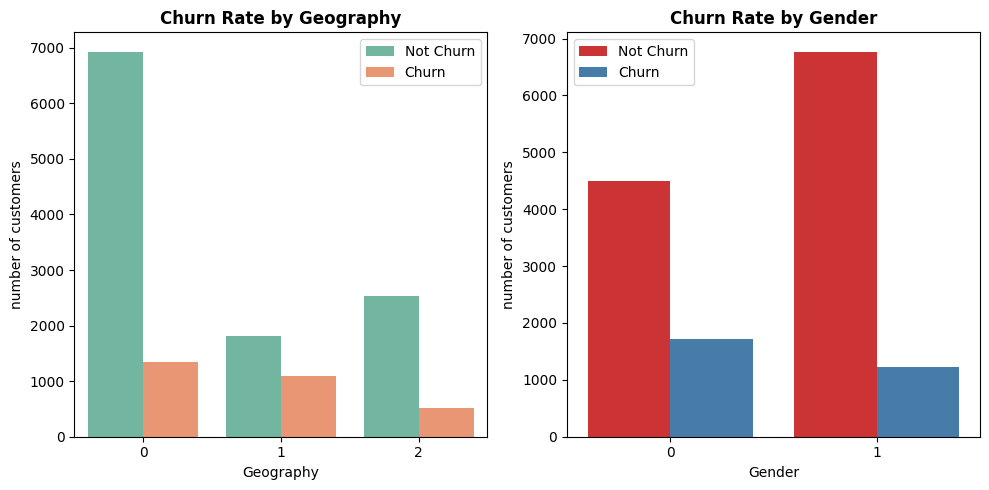

In [ ]:
plt.figure(figsize=(10, 5))

# رسم مقارنة المغادرة حسب الدولة
plt.subplot(1, 2, 1)
ax1 = sns.countplot(x='Geography', hue='Exited', data=df, palette='Set2')
plt.title('Churn Rate by Geography', fontweight='bold')
plt.ylabel('number of customers')
plt.legend(['Not Churn', 'Churn'])

# رسم مقارنة المغادرة حسب النوع
plt.subplot(1, 2, 2)
ax2 = sns.countplot(x='Gender', hue='Exited', data=df, palette='Set1')
plt.title('Churn Rate by Gender', fontweight='bold')
plt.ylabel('number of customers')
plt.legend(['Not Churn', 'Churn'])

plt.tight_layout()
plt.savefig('demographics_churn.png', dpi=150)
plt.show()

/tmp/ipykernel_456/1118413024.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Exited', y='Age', data=df, palette=['#2E86AB', '#E63946'])
/tmp/ipykernel_456/1118413024.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Exited', y='Balance', data=df, palette=['#2E86AB', '#E63946'])


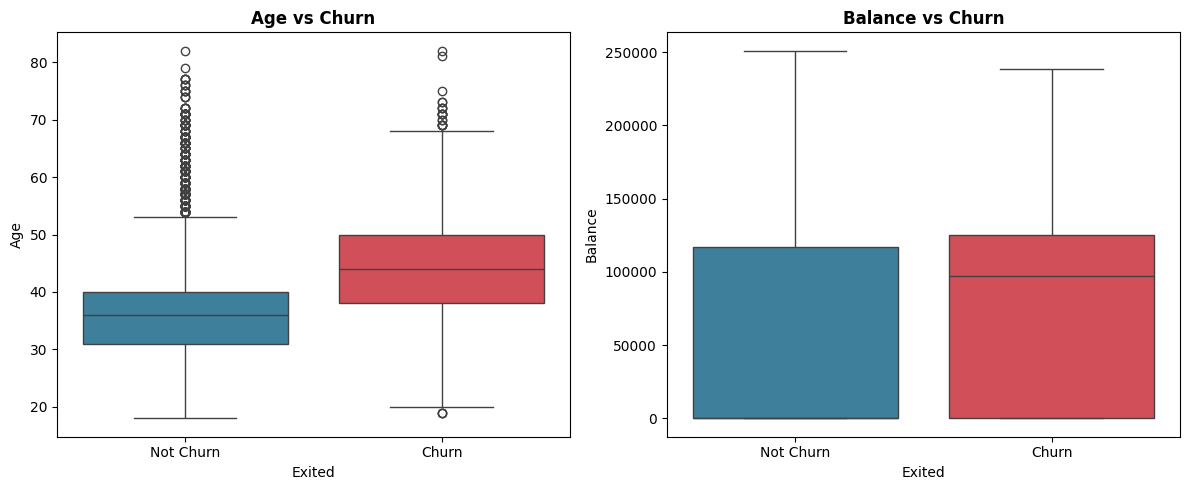

In [ ]:
plt.figure(figsize=(12, 5))

# مقارنة الأعمار
plt.subplot(1, 2, 1)
sns.boxplot(x='Exited', y='Age', data=df, palette=['#2E86AB', '#E63946'])
plt.xticks([0, 1], ['Not Churn', 'Churn'])
plt.title('Age vs Churn', fontweight='bold')

# مقارنة الأرصدة
plt.subplot(1, 2, 2)
sns.boxplot(x='Exited', y='Balance', data=df, palette=['#2E86AB', '#E63946'])
plt.xticks([0, 1], ['Not Churn', 'Churn'])
plt.title('Balance vs Churn', fontweight='bold')

plt.tight_layout()
plt.savefig('numeric_features_churn.png', dpi=150)
plt.show()

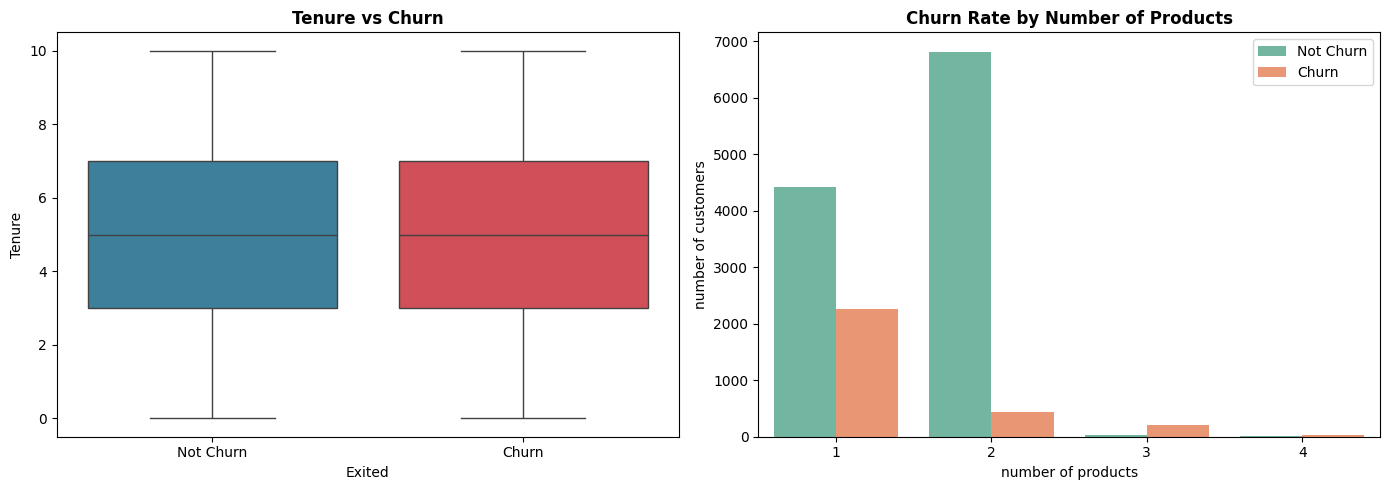

In [ ]:
plt.figure(figsize=(14, 5))

# مقارنة مدة الولاء (Tenure)
plt.subplot(1, 2, 1)
sns.boxplot(x='Exited', y='Tenure', data=df, hue='Exited', palette=['#2E86AB', '#E63946'], legend=False)
plt.xticks([0, 1], ['Not Churn', 'Churn'])
plt.title('Tenure vs Churn', fontweight='bold')

# تأثير عدد المنتجات (NumOfProducts)
plt.subplot(1, 2, 2)
ax = sns.countplot(x='NumOfProducts', hue='Exited', data=df, palette='Set2')
plt.title('Churn Rate by Number of Products', fontweight='bold')
plt.ylabel('number of customers')
plt.xlabel('number of products')
plt.legend(['Not Churn', 'Churn'])

plt.tight_layout()
plt.savefig('tenure_products_churn.png', dpi=150)
plt.show()

/tmp/ipykernel_456/325256899.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(['Not Active (0)', 'Active (1)'])
/tmp/ipykernel_456/325256899.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(['No Credit Card (0)', 'Has Credit Card (1)'])


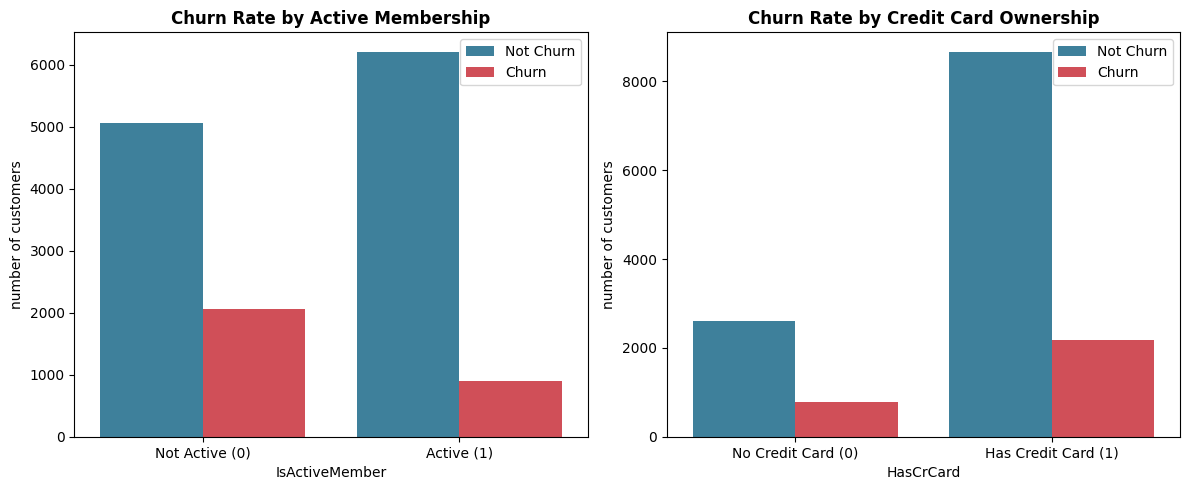

In [ ]:
plt.figure(figsize=(12, 5))

# تأثير العضوية النشطة
plt.subplot(1, 2, 1)
ax1 = sns.countplot(x='IsActiveMember', hue='Exited', data=df, palette=['#2E86AB', '#E63946'])
ax1.set_xticklabels(['Not Active (0)', 'Active (1)'])
plt.title('Churn Rate by Active Membership', fontweight='bold')
plt.ylabel('number of customers')
plt.legend(['Not Churn', 'Churn'])

# تأثير بطاقة الائتمان
plt.subplot(1, 2, 2)
ax2 = sns.countplot(x='HasCrCard', hue='Exited', data=df, palette=['#2E86AB', '#E63946'])
ax2.set_xticklabels(['No Credit Card (0)', 'Has Credit Card (1)'])
plt.title('Churn Rate by Credit Card Ownership', fontweight='bold')
plt.ylabel('number of customers')
plt.legend(['Not Churn', 'Churn'])

plt.tight_layout()
plt.savefig('activity_credit_churn.png', dpi=150)
plt.show()

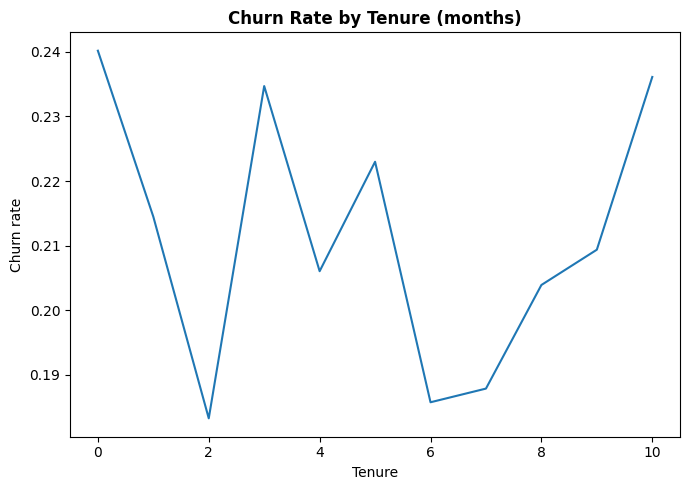

In [ ]:
plt.figure(figsize=(7, 5))
sns.lineplot(data=df, x='Tenure', y='Exited', errorbar=None)
plt.title('Churn Rate by Tenure (months)', fontweight='bold')
plt.ylabel('Churn rate')
plt.tight_layout()
plt.show()

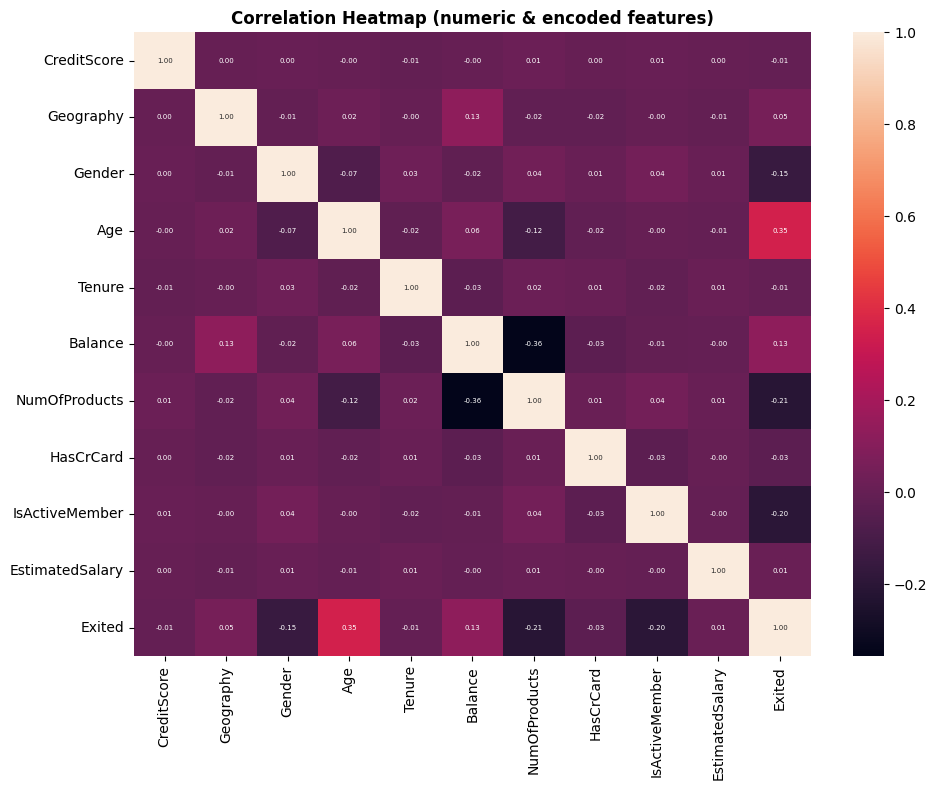

In [ ]:
num_cols = list(df.select_dtypes(include='number').columns)

plt.figure(figsize=(10 , 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='rocket',
            annot_kws={"size": 5}, cbar=True)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.title('Correlation Heatmap (numeric & encoded features)', fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
X = df.drop(columns=['Exited'])
y = df['Exited']

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
# Drop rows where target variable 'Exited' is missing, then redefine X and y
df_clean = df.dropna(subset=['Exited'])
X_clean = df_clean.drop(columns=['Exited'])
y_clean = df_clean['Exited']

X_train, X_test, y_train, y_test = train_test_split(X_clean, y_clean, test_size=0.2, random_state=42, stratify=y_clean)

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
import time
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import LinearSVC # استخدمنا هذا لتسريع الـ SVM بشكل جنوني
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report
)

# قائمة النماذج (تم استبدال SVC الثقيل بـ LinearSVC السريع للبيانات الضخمة)
models = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVM (Linear)": LinearSVC(random_state=42, max_iter=5000), # أسرع بكثير جداً من SVC
    "Naive Bayes": GaussianNB(),
    # "KNN": KNeighborsClassifier(), # يُفضل حذفه إذا كانت البيانات ضخمة لأنه يبطئ التنبؤ جداً
}

results = []

for name, model in models.items():
    print(f" Training and evaluating: {name}...")
    start_time = time.time()

    # التدريب مرة واحدة فقط
    model.fit(X_train_scaled, y_train)

    # التنبؤ
    y_pred_train = model.predict(X_train_scaled)
    y_pred_test = model.predict(X_test_scaled)

    # فحص دعم الاحتمالات لحساب ROC-AUC
    if hasattr(model, "predict_proba"):
        y_proba_test = model.predict_proba(X_test_scaled)[:, 1]
    elif hasattr(model, "decision_function"):
        # للـ LinearSVC الذي لا يدعم predict_proba مباشرة بشكل افتراضي
        y_proba_test = model.decision_function(X_test_scaled)
    else:
        y_proba_test = y_pred_test # كاحتياط

    auc_score = roc_auc_score(y_test, y_proba_test)

    # طباعة التقرير السريع
    print(f"-> Done in {time.time() - start_time:.2f} seconds\n")

    # حفظ النتائج مباشرة
    results.append({
        'Model': name,
        'Train Accuracy': accuracy_score(y_train, y_pred_train),
        'Test Accuracy': accuracy_score(y_test, y_pred_test),
        'Precision (Churn)': precision_score(y_test, y_pred_test, zero_division=0),
        'Recall (Churn)': recall_score(y_test, y_pred_test, zero_division=0),
        'F1 (Churn)': f1_score(y_test, y_pred_test, zero_division=0),
        'ROC-AUC': auc_score,
    })

# بناء جدول النتائج النهائي وترتيبه
results_df = pd.DataFrame(results).sort_values('F1 (Churn)', ascending=False).reset_index(drop=True)

# عرض الجدول ملوناً
display(results_df.style.background_gradient(cmap='Greens', subset=['F1 (Churn)', 'ROC-AUC', 'Recall (Churn)']))

 Training and evaluating: Logistic Regression...
-> Done in 0.03 seconds

 Training and evaluating: Decision Tree...
-> Done in 0.11 seconds

 Training and evaluating: Random Forest...
-> Done in 2.19 seconds

 Training and evaluating: Gradient Boosting...
-> Done in 2.12 seconds

 Training and evaluating: SVM (Linear)...
-> Done in 0.02 seconds

 Training and evaluating: Naive Bayes...
-> Done in 0.02 seconds



,Model,Train Accuracy,Test Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),ROC-AUC
0,Gradient Boosting,0.870440,0.859402,0.742347,0.493220,0.592668,0.872186
1,Random Forest,0.999824,0.850967,0.699519,0.493220,0.578529,0.856671
2,Decision Tree,1.000000,0.794728,0.505017,0.511864,0.508418,0.690300
3,Naive Bayes,0.829568,0.823550,0.627168,0.367797,0.463675,0.822513
4,Logistic Regression,0.830711,0.821441,0.642361,0.313559,0.421412,0.793711
5,SVM (Linear),0.826316,0.822496,0.672065,0.281356,0.396655,0.794400


#معالجه قويه

In [ ]:
# ==========================================
# 1. معالجة عدم توازن البيانات باستخدام SMOTE
# ==========================================
from imblearn.over_sampling import SMOTE

print(" Applying SMOTE to balance the training data...")
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

print(f"Before SMOTE - Training shape: {X_train_scaled.shape}, Churn count: {sum(y_train == 1)}")
print(f"After SMOTE  - Training shape: {X_train_resampled.shape}, Churn count: {sum(y_train_resampled == 1)}\n")


 Applying SMOTE to balance the training data...
Before SMOTE - Training shape: (11377, 10), Churn count: 2359
After SMOTE  - Training shape: (18036, 10), Churn count: 9018



In [ ]:
# ==========================================
# 2. ضبط المعلمات (Hyperparameter Tuning) لـ Random Forest
# ==========================================
from sklearn.model_selection import GridSearchCV

print(" Tuning Random Forest hyperparameters using GridSearchCV...")
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

rf_base = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(estimator=rf_base, param_grid=param_grid, cv=3, scoring='f1', n_jobs=-1)
grid_search.fit(X_train_resampled, y_train_resampled)

best_rf = grid_search.best_estimator_
print(f"-> Best Parameters Found: {grid_search.best_params_}\n")

 Tuning Random Forest hyperparameters using GridSearchCV...
-> Best Parameters Found: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 200}



In [ ]:
# ==========================================
# 3. بناء النموذج المدمج (Voting Classifier)
# ==========================================
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

print(" Building an Ensemble Voting Classifier (Logistic Regression + Best RF + Decision Tree)...")

# تجهيز النماذج الفردية الأفضل للدمج
clf1 = LogisticRegression(max_iter=5000, random_state=42)
clf2 = best_rf
clf3 = DecisionTreeClassifier(random_state=42)

voting_clf = VotingClassifier(
    estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)],
    voting='soft' # استخدام الاحتمالات لدمج القرارات بدقة أعلى
)

# التدريب على البيانات المتوازنة (بعد SMOTE)
voting_clf.fit(X_train_resampled, y_train_resampled)

# التنبؤ والتقييم للنموذج المدمج النهائي
y_pred_voting = voting_clf.predict(X_test_scaled)
y_proba_voting = voting_clf.predict_proba(X_test_scaled)[:, 1]

print("\n" + "="*40)
print(" Final Voting Classifier Performance Report:")
print("="*40)
print(classification_report(y_test, y_pred_voting))
print(f"Final Voting Classifier ROC-AUC Score: {roc_auc_score(y_test, y_proba_voting):.4f}")

 Building an Ensemble Voting Classifier (Logistic Regression + Best RF + Decision Tree)...

 Final Voting Classifier Performance Report:
              precision    recall  f1-score   support

           0       0.89      0.85      0.87      2255
           1       0.50      0.59      0.54       590

    accuracy                           0.79      2845
   macro avg       0.70      0.72      0.70      2845
weighted avg       0.81      0.79      0.80      2845

Final Voting Classifier ROC-AUC Score: 0.8315


#شكل كلمه overfiting

In [ ]:
# Use the active ensemble model and resampled training data present in your kernel
train_pred = voting_clf.predict(X_train_resampled)
train_acc = accuracy_score(y_train_resampled, train_pred)

# Predict on the scaled test set
y_pred_voting = voting_clf.predict(X_test_scaled)
test_acc = accuracy_score(y_test, y_pred_voting)

print("Model:", voting_clf.__class__.__name__)
print("Train Accuracy (Balanced Dataset):", train_acc)
print("Test Accuracy:", test_acc)

Model: VotingClassifier
Train Accuracy (Balanced Dataset): 1.0
Test Accuracy: 0.79402460456942


#حل للover

In [ ]:
RandomForestClassifier(
    max_depth=10,
    min_samples_split=5
)

RandomForestClassifier(max_depth=10, min_samples_split=5)

In [ ]:
from sklearn.model_selection import cross_val_score

# Evaluate the active voting classifier model with cross-validation on resampled data
scores = cross_val_score(voting_clf, X_train_resampled, y_train_resampled, cv=3, n_jobs=-1)
print("Cross-Validation Scores:", scores)
print("Mean CV Accuracy:", scores.mean())

Cross-Validation Scores: [0.81087824 0.86676647 0.87142382]
Mean CV Accuracy: 0.8496895098691506


In [ ]:
RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

RandomForestClassifier(max_depth=10, min_samples_leaf=5, min_samples_split=10,
                       n_estimators=200, random_state=42)

In [ ]:
SMOTE(sampling_strategy=0.6)

SMOTE(sampling_strategy=0.6)

In [ ]:
from sklearn.model_selection import cross_val_score

# Using the resampled data and active ensemble model present in your notebook
scores = cross_val_score(voting_clf, X_train_resampled, y_train_resampled, cv=5, n_jobs=-1)

print("Cross-Validation Scores:", scores)
print("Mean CV Accuracy:", scores.mean())

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Cross-Validation Scores: [0.79268293 0.85639035 0.87025229 0.88328251 0.88023288]
Mean CV Accuracy: 0.8565681905779414


In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif
selector = SelectKBest(score_func=f_classif, k=8)
X = selector.fit_transform(X, y)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
#smote
smote = SMOTE(sampling_strategy=0.6, random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [150, 200],
    'max_depth': [8, 10],
    'min_samples_split': [5, 10],
    'min_samples_leaf': [3, 5]
}
rf = RandomForestClassifier(random_state=42)

grid = GridSearchCV(
    rf,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_train_balanced, y_train_balanced)

best_model = grid.best_estimator_

print("Best Parameters:", grid.best_params_)

Best Parameters: {'max_depth': 10, 'min_samples_leaf': 3, 'min_samples_split': 5, 'n_estimators': 200}


In [ ]:
cv_scores = cross_val_score(
    best_model,
    X_train_balanced,
    y_train_balanced,
    cv=5
)

print("Cross Validation Mean:", cv_scores.mean())


Cross Validation Mean: 0.8392847582291306


In [ ]:
best_model.fit(X_train_balanced, y_train_balanced)

RandomForestClassifier(max_depth=10, min_samples_leaf=3, min_samples_split=5,
                       n_estimators=200, random_state=42)

In [ ]:
train_pred = best_model.predict(X_train_balanced)
train_acc = accuracy_score(y_train_balanced, train_pred)

y_pred = best_model.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)

print("Train Accuracy:", train_acc)
print("Test Accuracy:", test_acc)

Train Accuracy: 0.8745042043471363
Test Accuracy: 0.8511835012889618


In [ ]:
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))


Classification Report:

              precision    recall  f1-score   support

           0       0.91      0.90      0.91      3394
           1       0.63      0.67      0.65       873

    accuracy                           0.85      4267
   macro avg       0.77      0.78      0.78      4267
weighted avg       0.85      0.85      0.85      4267



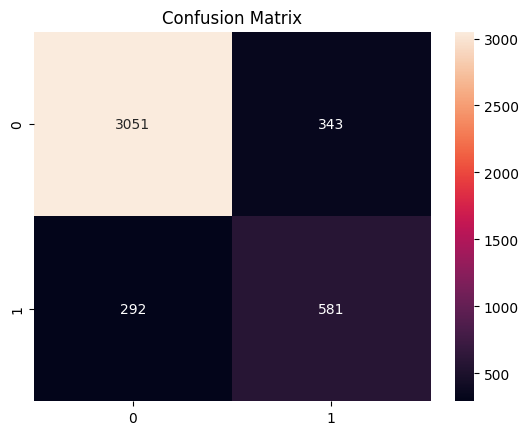

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()

In [ ]:
# Use the active model and balanced training data present in your kernel
train_pred = best_model.predict(X_train_balanced)
train_acc = accuracy_score(y_train_balanced, train_pred)

# Predict on the active test set (X_test has been transformed using the correct scaler)
y_pred_active = best_model.predict(X_test)
test_acc = accuracy_score(y_test, y_pred_active)

print("Model:", best_model.__class__.__name__)
print("Train Accuracy (Balanced Dataset):", train_acc)
print("Test Accuracy:", test_acc)

Model: RandomForestClassifier
Train Accuracy (Balanced Dataset): 0.8745042043471363
Test Accuracy: 0.8511835012889618


In [ ]:
"""import joblib

joblib.dump(best_model, 'model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(selector, 'selector.pkl')
joblib.dump(selector.get_feature_names_out(), 'columns.pkl')

print("✅ Model saved correctly")"""

In [ ]:
'''from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, auc, roc_auc_score, confusion_matrix, classification_report)'''

In [ ]:
'''from sklearn.calibration import CalibratedClassifierCV'''

In [ ]:
'''models = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVM (Support Vector Classifier)": CalibratedClassifierCV(SVC(random_state=42)), # probability=True مطلوبة لحساب الـ ROC-AUC
    "Naive Bayes": GaussianNB(),
    'KNN': KNeighborsClassifier(),
}'''

In [ ]:
'''# Initialize a model instance before training
model = RandomForestClassifier(random_state=42)

X_train_sample, y_train_sample = X_train_scaled[:5000], y_train[:5000]
model.fit(X_train_sample, y_train_sample)'''

In [ ]:
'''for name, model in models.items():
    print("=" * 10)
    print(f"Model: {name}")
    print("=" * 10)

    # التدريب
    model.fit(X_train_scaled, y_train)

    # التنبؤ بالأصل
    y_pred = model.predict(X_test_scaled)

    # طباعة التقرير
    print("Classification Report:")
    print(classification_report(y_test, y_pred))

    # فحص ما إذا كان النموذج يدعم حساب الاحتمالات (لتجنب تعليق الـ SVM)
    if hasattr(model, "predict_proba"):
        y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
        auc_score = roc_auc_score(y_test, y_pred_proba)
        print(f"ROC-AUC Score: {auc_score:.4f}\n")
    else:
        print("ROC-AUC Score: Not Available (Model doesn't support predict_proba by default)\n")'''

In [ ]:
'''results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred_train = model.predict(X_train_scaled)
    y_pred_test = model.predict(X_test_scaled)
    y_proba_test = model.predict_proba(X_test_scaled)[:, 1]

    results.append({
        'Model': name,
        'Train Accuracy': accuracy_score(y_train, y_pred_train),
        'Test Accuracy': accuracy_score(y_test, y_pred_test),
        'Precision (Churn)': precision_score(y_test, y_pred_test),
        'Recall (Churn)': recall_score(y_test, y_pred_test),
        'F1 (Churn)': f1_score(y_test, y_pred_test),
        'ROC-AUC': roc_auc_score(y_test, y_proba_test),
    })

results_df = pd.DataFrame(results).sort_values('F1 (Churn)', ascending=False).reset_index(drop=True)
results_df.style.background_gradient(cmap='Greens', subset=['F1 (Churn)', 'ROC-AUC', 'Recall (Churn)'])'''